# Task 3: XGBoost Regression & Classification

Predicts PM2.5 at t+1 / t+2 / t+3 (regression) and `is_health_risk` at t+1 / t+2 / t+3 (classification).

**Uses the team's `splitting.py`** for the feature list and CV folds (nothing is re-implemented here).

Two experiments are run and saved separately:
- `no_current`: the Week 3 brief's default (today's PM2.5 is NOT a feature, newest PM2.5 info is `lag_1d`)
- `with_current`: today's `pm2_5_corrected` / `is_health_risk` / `aqi_class` are added as features

Confirm with the team which one is "official" so every model is compared on the same footing.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             mean_absolute_percentage_error, precision_score,
                             recall_score, f1_score, roc_auc_score)

import splitting as sp   

pd.set_option("display.width", 200, "display.max_columns", 40)

df = pd.read_parquet("prepared_dataset.parquet")
print(df.shape)
df.head(3)

(5430, 123)


,station_id,day,uv_index,s5p_no2_col,s5p_o3_col,s5p_no2_col_gap_days,s5p_no2_col_is_observed,s5p_o3_col_gap_days,s5p_o3_col_is_observed,road_length_km_3000,road_density_kmkm2_3000,intersection_count_3000,intersection_density_3000,street_length_avg_3000,circuity_avg_3000,major_road_km_3000,major_road_share_3000,road_length_km_5000,road_density_kmkm2_5000,intersection_count_5000,...,inversion_proxy,inversion_proxy_v2,station_id_encoded,station_downtown,station_helwan,station_new_cairo,station_october,station_shobra,day_of_week_enc,season_enc,aqi_class,target_1d,target_risk_1d,target_aqi_1d,target_2d,target_risk_2d,target_aqi_2d,target_3d,target_risk_3d,target_aqi_3d
0,downtown,2023-09-08,2.222917,0.000084,0.126125,0.0,1,0.0,1,1404.083,49.659,10712,378.86,46.56,1.0304,143.803,0.1024,4427.74,56.376,32172,...,804.506716,3.723017,0,1,0,0,0,0,4,3,2,57.969833,1,2,53.737000,0,1,52.262472,0,1
1,downtown,2023-09-09,2.027083,0.000237,0.126131,0.0,1,0.0,1,1404.083,49.659,10712,378.86,46.56,1.0304,143.803,0.1024,4427.74,56.376,32172,...,1001.959215,4.170486,0,1,0,0,0,0,5,3,2,53.737000,0,1,52.262472,0,1,50.787944,0,1
2,downtown,2023-09-10,2.175000,0.000289,0.126218,0.0,1,0.0,1,1404.083,49.659,10712,378.86,46.56,1.0304,143.803,0.1024,4427.74,56.376,32172,...,1110.104130,4.650576,0,1,0,0,0,0,6,3,1,52.262472,0,1,50.787944,0,1,49.313417,0,1


In [2]:
sp.validate(df)

OK  no NaN in features or targets
OK  target_{1,2,3}d == PM2.5 at t+h within each district
OK  PM2.5 lags/rolling means use days <= t-1 only (no look-ahead; valid for t+1..t+3)
OK  default feature set: 101 columns, current-day outcome and all targets excluded
OK  CV: all 5 districts in every train & test fold, expanding train, contiguous test blocks,
    purge gap = horizon (no label overlap), identical test rows for t+1/t+2/t+3


True

In [3]:
HORIZONS = (1, 2, 3)

REG_PARAMS = dict(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42)
CLF_PARAMS = dict(n_estimators=100, max_depth=6, learning_rate=0.1,
                  random_state=42, eval_metric="logloss")

VARIANTS = {"no_current": False, "with_current": True}

for tag, flag in VARIANTS.items():
    n = len(sp.feature_columns(df, include_current_day_outcome=flag, station_encoding="label"))
    print(f"{tag:13s}: {n} features")

no_current   : 101 features
with_current : 104 features


### Helpers

In [4]:
def district_groups(df_te):
    """'ALL' (pooled) plus one entry per district. Values are positional indices inside the test fold."""
    g = {"ALL": np.arange(len(df_te))}
    g.update(dict(df_te.groupby(sp.STATION_COL).indices))
    return g


def reg_metrics(y, p):
    return dict(rmse=float(np.sqrt(mean_squared_error(y, p))),
                mae=float(mean_absolute_error(y, p)),
                mape_pct=float(mean_absolute_percentage_error(y, p) * 100),   # in percent
                r2=float(r2_score(y, p)))


def summarize(res, metrics):
    """Mean and std (ddof=0, as in the first version) over the 5 folds, pooled rows only."""
    a = res[res.district == "ALL"]
    out = a.groupby("horizon")[metrics].agg(["mean", lambda x: x.std(ddof=0)])
    out.columns = [f"{m}_{'mean' if s == 'mean' else 'std'}" for m, s in out.columns]
    return out.reset_index()


def pretty(summary, metrics):
    t = pd.DataFrame({"horizon": summary["horizon"].map(lambda h: f"t+{h}")})
    for m in metrics:
        t[m] = [f"{a:.4f} +/- {b:.4f}" for a, b in zip(summary[f"{m}_mean"], summary[f"{m}_std"])]
    return t

## 1. Regression (t+1, t+2, t+3)

Key point: `get_cv_splits(df, horizon=h)` is called **per horizon**, so the purge gap equals the horizon
(no training label can fall in the test period). Test rows are identical across horizons, so results are comparable.

In [5]:
def run_regression(df, include_current):
    feats = sp.feature_columns(df, include_current_day_outcome=include_current, station_encoding="label")
    X = df[feats]
    rows = []
    for h in HORIZONS:
        y = df[f"target_{h}d"]
        for k, (tr, te) in enumerate(sp.get_cv_splits(df, horizon=h), 1):
            model = xgb.XGBRegressor(**REG_PARAMS).fit(X.iloc[tr], y.iloc[tr])
            pred = model.predict(X.iloc[te])
            yt = y.iloc[te].to_numpy()
            for d, ix in district_groups(df.iloc[te]).items():
                rows.append(dict(horizon=h, fold=k, district=d, **reg_metrics(yt[ix], pred[ix])))
        print(f"[{'with' if include_current else 'no'}_current] t+{h} done")
    return pd.DataFrame(rows), feats


REG_METRICS = ["rmse", "mae", "mape_pct", "r2"]
reg_results, reg_summary = {}, {}

for tag, flag in VARIANTS.items():
    res, feats = run_regression(df, flag)
    reg_results[tag] = res
    reg_summary[tag] = summarize(res, REG_METRICS)
    res.to_csv(f"xgb_regression_results_{tag}.csv", index=False)           # per fold x district
    reg_summary[tag].assign(model="XGBoost", variant=tag).to_csv(
        f"xgb_regression_summary_{tag}.csv", index=False)                  # for Task 6
    print(f"\n=== Regression summary: {tag} ({len(feats)} features) ===")
    print(pretty(reg_summary[tag], REG_METRICS).to_string(index=False))

[no_current] t+1 done
[no_current] t+2 done
[no_current] t+3 done

=== Regression summary: no_current (101 features) ===
horizon               rmse                mae           mape_pct                r2
    t+1 14.5954 +/- 4.7075 10.6854 +/- 3.2103 24.3538 +/- 3.6832 0.3222 +/- 0.0233
    t+2 16.6238 +/- 5.7636 12.4274 +/- 3.9984 28.5030 +/- 4.8162 0.0991 +/- 0.0539
    t+3 16.8841 +/- 5.7163 12.6793 +/- 3.8982 29.1315 +/- 4.2186 0.0475 +/- 0.0687
[with_current] t+1 done
[with_current] t+2 done
[with_current] t+3 done

=== Regression summary: with_current (104 features) ===
horizon               rmse                mae           mape_pct                r2
    t+1 13.3849 +/- 4.7112  9.6888 +/- 3.2320 21.3559 +/- 3.5367 0.4369 +/- 0.0497
    t+2 16.3284 +/- 5.8890 12.0974 +/- 4.0128 27.6320 +/- 4.6241 0.1381 +/- 0.0593
    t+3 16.8345 +/- 5.8537 12.6448 +/- 4.0542 28.9812 +/- 4.5206 0.0597 +/- 0.0595


### Per-fold detail (pooled), t+1 / default experiment

In [6]:
r = reg_results["no_current"]
r[(r.district == "ALL")].pivot(index="fold", columns="horizon", values="rmse").round(3)

horizon,1,2,3
fold,,,
1,17.195,19.656,20.067
2,12.258,14.151,14.092
3,10.331,11.583,12.274
4,22.613,26.458,26.587
5,10.581,11.270,11.401


### Horizon degradation: RMSE vs horizon per district

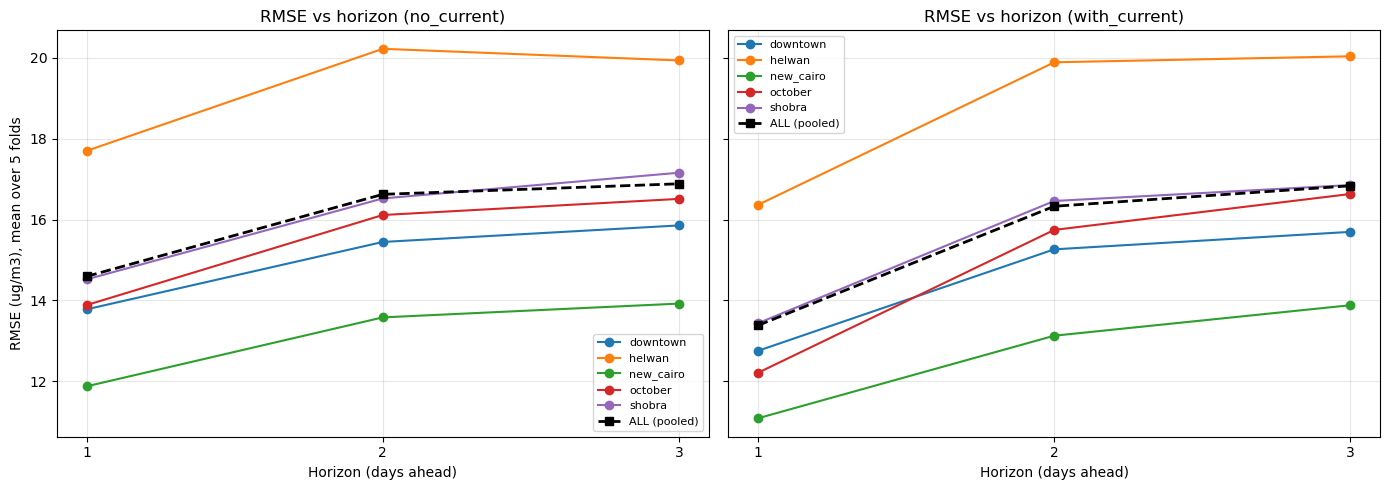

no_current: RMSE t+1 -> t+3 = 14.60 -> 16.88  (+15.7%)
with_current: RMSE t+1 -> t+3 = 13.38 -> 16.83  (+25.8%)


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (tag, res) in zip(axes, reg_results.items()):
    piv = res[res.district != "ALL"].groupby(["horizon", "district"]).rmse.mean().unstack()
    piv.plot(ax=ax, marker="o")
    pooled = res[res.district == "ALL"].groupby("horizon").rmse.mean()
    ax.plot(pooled.index, pooled.values, "k--", marker="s", linewidth=2, label="ALL (pooled)")
    ax.set_title(f"RMSE vs horizon ({tag})")
    ax.set_xlabel("Horizon (days ahead)"); ax.set_xticks(list(HORIZONS)); ax.grid(alpha=.3)
    ax.legend(fontsize=8)
axes[0].set_ylabel("RMSE (ug/m3), mean over 5 folds")
plt.tight_layout(); plt.savefig("xgb_rmse_vs_horizon.png", dpi=200); plt.show()

for tag, s in reg_summary.items():
    r1 = s.loc[s.horizon == 1, "rmse_mean"].item(); r3 = s.loc[s.horizon == 3, "rmse_mean"].item()
    print(f"{tag}: RMSE t+1 -> t+3 = {r1:.2f} -> {r3:.2f}  ({(r3 / r1 - 1) * 100:+.1f}%)")

### RMSE per district (mean over folds): which district is hardest? (is October?)

In [8]:
for tag, res in reg_results.items():
    print(f"\n{tag}")
    print(res[res.district != "ALL"].groupby(["district", "horizon"]).rmse.mean()
             .unstack().round(2).to_string())


no_current
horizon        1      2      3
district                      
downtown   13.78  15.45  15.86
helwan     17.70  20.22  19.93
new_cairo  11.88  13.58  13.92
october    13.89  16.11  16.51
shobra     14.52  16.52  17.16

with_current
horizon        1      2      3
district                      
downtown   12.76  15.26  15.70
helwan     16.36  19.89  20.04
new_cairo  11.09  13.13  13.88
october    12.21  15.74  16.63
shobra     13.44  16.46  16.85


## 2. Classification: `is_health_risk` (t+1, t+2, t+3)

Run **with** `scale_pos_weight = N_neg / N_pos` (computed on the train fold only) and **without** it,
to measure how much class weighting changes recall. Recall on the positive class is the key metric.

In [9]:
def run_classification(df, include_current, weighted):
    feats = sp.feature_columns(df, include_current_day_outcome=include_current, station_encoding="label")
    X = df[feats]
    rows = []
    for h in HORIZONS:
        y = df[f"target_risk_{h}d"]
        for k, (tr, te) in enumerate(sp.get_cv_splits(df, horizon=h), 1):
            spw = sp.scale_pos_weight(y.iloc[tr]) if weighted else 1.0
            model = xgb.XGBClassifier(scale_pos_weight=spw, **CLF_PARAMS).fit(X.iloc[tr], y.iloc[tr])
            pred = model.predict(X.iloc[te])
            prob = model.predict_proba(X.iloc[te])[:, 1]
            yt = y.iloc[te].to_numpy()
            for d, ix in district_groups(df.iloc[te]).items():
                has_pos = yt[ix].sum() > 0
                has_both = len(np.unique(yt[ix])) > 1
                rec = recall_score(yt[ix], pred[ix], zero_division=0) if has_pos else np.nan
                rows.append(dict(
                    horizon=h, fold=k, district=d, weighted=weighted, scale_pos_weight=spw,
                    pos_rate_test=float(yt[ix].mean()),
                    precision=precision_score(yt[ix], pred[ix], zero_division=0),
                    recall=rec,
                    f1=f1_score(yt[ix], pred[ix], zero_division=0),
                    auc_roc=roc_auc_score(yt[ix], prob[ix]) if has_both else np.nan,
                    false_negative_rate=(1 - rec) if has_pos else np.nan))
        print(f"[{'with' if include_current else 'no'}_current | weighted={weighted}] t+{h} done")
    return pd.DataFrame(rows)


CLF_METRICS = ["precision", "recall", "f1", "auc_roc"]
clf_results, clf_summary = {}, {}

for tag, flag in VARIANTS.items():
    res = pd.concat([run_classification(df, flag, True), run_classification(df, flag, False)],
                    ignore_index=True)
    clf_results[tag] = res
    res.to_csv(f"xgb_classification_results_{tag}.csv", index=False)       # per fold x district x weighting
    s = (res[res.district == "ALL"].groupby(["weighted", "horizon"])[CLF_METRICS]
            .agg(["mean", lambda x: x.std(ddof=0)]))
    s.columns = [f"{m}_{'mean' if a == 'mean' else 'std'}" for m, a in s.columns]
    clf_summary[tag] = s.reset_index()
    clf_summary[tag].assign(model="XGBoost", variant=tag).to_csv(
        f"xgb_classification_summary_{tag}.csv", index=False)              # for Task 6
    print(f"\n=== Classification summary: {tag} (pooled districts, mean/std over 5 folds) ===")
    show = clf_summary[tag].copy()
    for m in CLF_METRICS:
        show[m] = [f"{a:.3f} +/- {b:.3f}" for a, b in zip(show[f"{m}_mean"], show[f"{m}_std"])]
    print(show[["weighted", "horizon"] + CLF_METRICS].to_string(index=False))

[no_current | weighted=True] t+1 done
[no_current | weighted=True] t+2 done
[no_current | weighted=True] t+3 done
[no_current | weighted=False] t+1 done
[no_current | weighted=False] t+2 done
[no_current | weighted=False] t+3 done

=== Classification summary: no_current (pooled districts, mean/std over 5 folds) ===
 weighted  horizon       precision          recall              f1         auc_roc
    False        1 0.571 +/- 0.114 0.336 +/- 0.161 0.412 +/- 0.167 0.796 +/- 0.030
    False        2 0.445 +/- 0.142 0.197 +/- 0.168 0.252 +/- 0.182 0.680 +/- 0.092
    False        3 0.353 +/- 0.257 0.174 +/- 0.180 0.217 +/- 0.207 0.648 +/- 0.068
     True        1 0.514 +/- 0.103 0.443 +/- 0.171 0.469 +/- 0.150 0.794 +/- 0.031
     True        2 0.403 +/- 0.136 0.285 +/- 0.198 0.316 +/- 0.178 0.680 +/- 0.068
     True        3 0.316 +/- 0.201 0.267 +/- 0.246 0.277 +/- 0.224 0.638 +/- 0.083
[with_current | weighted=True] t+1 done
[with_current | weighted=True] t+2 done
[with_current | weight

### Impact of class weighting on recall (default experiment)

In [10]:
for tag in VARIANTS:
    s = clf_summary[tag]
    cmp = s.pivot(index="horizon", columns="weighted", values=["recall_mean", "precision_mean", "f1_mean"]).round(3)
    cmp.columns = [f"{m.replace('_mean','')}_{'weighted' if w else 'unweighted'}" for m, w in cmp.columns]
    print(f"\n{tag}")
    print(cmp.to_string())


no_current
         recall_unweighted  recall_weighted  precision_unweighted  precision_weighted  f1_unweighted  f1_weighted
horizon                                                                                                          
1                    0.336            0.443                 0.571               0.514          0.412        0.469
2                    0.197            0.285                 0.445               0.403          0.252        0.316
3                    0.174            0.267                 0.353               0.316          0.217        0.277

with_current
         recall_unweighted  recall_weighted  precision_unweighted  precision_weighted  f1_unweighted  f1_weighted
horizon                                                                                                          
1                    0.420            0.505                 0.642               0.566          0.495        0.522
2                    0.208            0.309                 0.

### Why are some folds weak? (recall per fold vs positive rate in the test block)

If a fold has very few positive days, or a very different positive rate from train, recall swings a lot.
Use this table to explain fold 5 in the write-up.

In [11]:
a = clf_results["no_current"]
a = a[(a.district == "ALL") & (a.weighted)]
print(a.pivot(index="fold", columns="horizon", values="recall").round(3).add_prefix("recall_t+").join(
      a[a.horizon == 1].set_index("fold")[["pos_rate_test", "scale_pos_weight"]].round(3)).to_string())
print("\nClass balance per fold (from splitting.py, horizon=1):")
sp.class_balance(df, 1).round(3)

      recall_t+1  recall_t+2  recall_t+3  pos_rate_test  scale_pos_weight
fold                                                                     
1          0.632       0.573       0.596          0.330             3.691
2          0.442       0.224       0.115          0.178             3.154
3          0.391       0.116       0.071          0.102             3.359
4          0.597       0.455       0.534          0.441             3.800
5          0.153       0.056       0.020          0.087             3.156

Class balance per fold (from splitting.py, horizon=1):


,fold,n_train,n_test,pos_rate_train,pos_rate_test,n_pos_train,n_pos_test,scale_pos_weight_train,test_pos_downtown,test_pos_helwan,test_pos_new_cairo,test_pos_october,test_pos_shobra
0,1,2050,675,0.213,0.330,437,223,3.691,0.519,0.400,0.178,0.059,0.496
1,2,2725,675,0.241,0.178,656,120,3.154,0.215,0.244,0.096,0.163,0.170
2,3,3400,675,0.229,0.102,780,69,3.359,0.170,0.170,0.059,0.044,0.067
3,4,4075,675,0.208,0.441,849,298,3.800,0.526,0.593,0.296,0.274,0.519
4,5,4750,675,0.241,0.087,1143,59,3.156,0.037,0.185,0.022,0.170,0.022


### Recall on the positive class per district (t+1, weighted, default experiment)

horizon    recall_t+1  recall_t+2  recall_t+3
district                                     
downtown        0.613       0.475       0.435
helwan          0.414       0.140       0.221
new_cairo       0.297       0.138       0.146
october         0.161       0.054       0.081
shobra          0.571       0.511       0.314


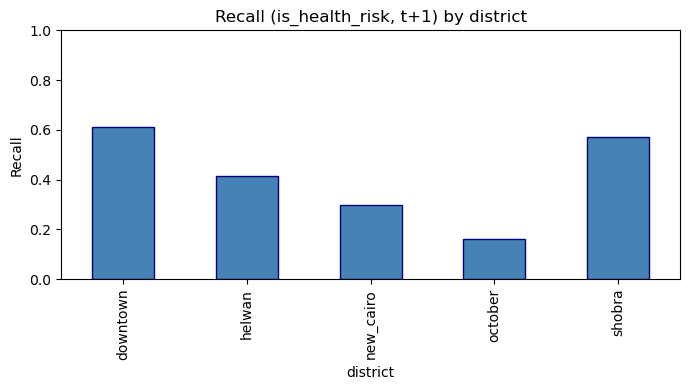

In [12]:
d = clf_results["no_current"]
d = d[(d.weighted) & (d.district != "ALL")]
print(d.groupby(["district", "horizon"]).recall.mean().unstack().round(3).add_prefix("recall_t+").to_string())

d[d.horizon == 1].groupby("district").recall.mean().plot(kind="bar", color="steelblue", edgecolor="navy",
                                                          figsize=(7, 4), title="Recall (is_health_risk, t+1) by district")
plt.ylabel("Recall"); plt.ylim(0, 1); plt.tight_layout(); plt.savefig("xgb_recall_by_district.png", dpi=200); plt.show()

## 3. Feature importance (XGBoost gain, t+1 regression)

Trained on the **last** CV fold (largest training set). Change `FOLD_FOR_IMPORTANCE` if the team prefers fold 1.

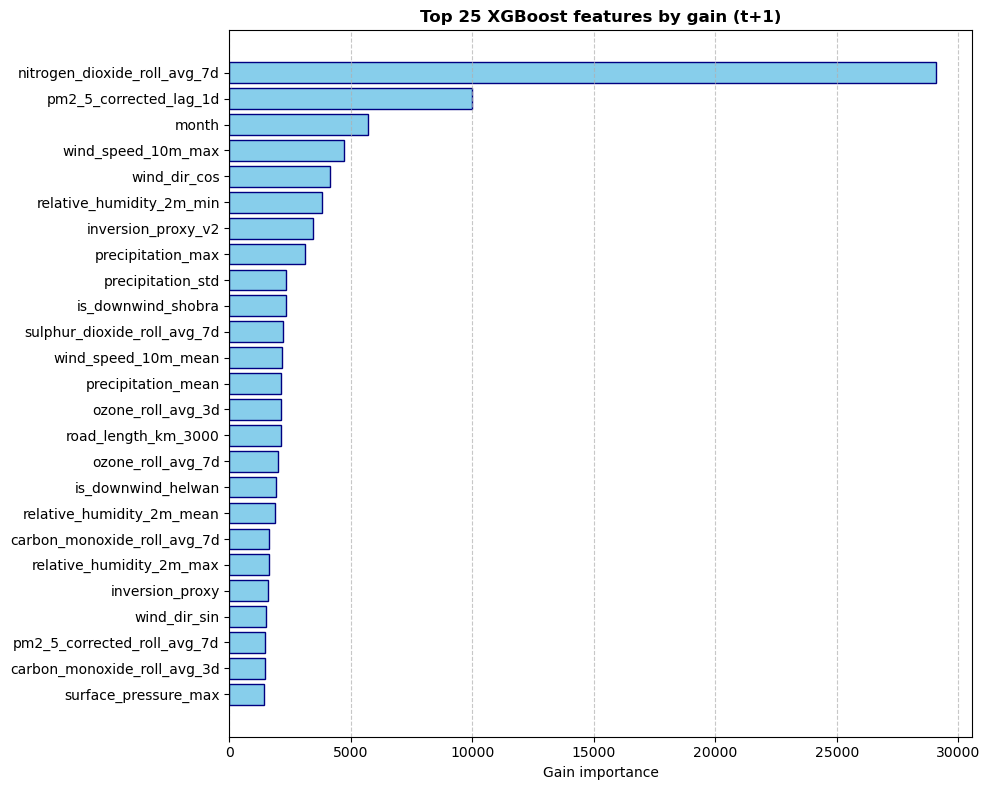

[is_downwind_helwan] rank 17 of 101 | gain 1900.5 | IN top 25
[inversion_proxy_v2] rank 7 of 101 | gain 3452.6 | IN top 25
[dust_transport_proxy] rank 27 of 101 | gain 1359.8 | BELOW top 25


In [13]:
FOLD_FOR_IMPORTANCE = -1   # -1 = last fold

feats = sp.feature_columns(df, include_current_day_outcome=False, station_encoding="label")
tr, te = sp.get_cv_splits(df, horizon=1)[FOLD_FOR_IMPORTANCE]
model = xgb.XGBRegressor(**REG_PARAMS).fit(df.iloc[tr][feats], df.iloc[tr]["target_1d"])

imp = pd.Series(model.get_booster().get_score(importance_type="gain")).reindex(feats).fillna(0.0)
imp_df = (imp.sort_values(ascending=False).rename_axis("feature").reset_index(name="gain"))
imp_df["rank"] = np.arange(1, len(imp_df) + 1)
imp_df.to_csv("xgboost_feature_importance_all.csv", index=False)

top25 = imp_df.head(25)
with open("xgboost_top_features.txt", "w") as f:
    f.write("Top 25 features by XGBoost gain (t+1 regression)\n" + "=" * 50 + "\n\n")
    f.write(top25.to_string(index=False))

top25s = top25.iloc[::-1]
plt.figure(figsize=(10, 8))
plt.barh(top25s["feature"], top25s["gain"], color="skyblue", edgecolor="navy")
plt.xlabel("Gain importance"); plt.title("Top 25 XGBoost features by gain (t+1)", fontweight="bold")
plt.grid(axis="x", linestyle="--", alpha=.7); plt.tight_layout()
plt.savefig("xgboost_top_features.png", dpi=300); plt.show()

for feat in ["is_downwind_helwan", "inversion_proxy_v2", "dust_transport_proxy"]:
    row = imp_df[imp_df.feature == feat]
    if len(row):
        print(f"[{feat}] rank {int(row['rank'].iloc[0])} of {len(imp_df)} | gain {row['gain'].iloc[0]:.1f} "
              f"| {'IN top 25' if row['rank'].iloc[0] <= 25 else 'BELOW top 25'}")
    else:
        print(f"[{feat}] not in feature list")

## 4. Write-up notes

**Headline experiment:** `no_current` (brief default). `with_current` is reported as a sensitivity check.

### Regression: horizon degradation
| Horizon | RMSE | MAE | MAPE | R² |
|---|---|---|---|---|
| t+1 | 14.60 ± 4.71 | 10.69 ± 3.21 | 24.4% | 0.322 ± 0.023 |
| t+2 | 16.62 ± 5.76 | 12.43 ± 4.00 | 28.5% | 0.099 ± 0.054 |
| t+3 | 16.88 ± 5.72 | 12.68 ± 3.90 | 29.1% | 0.048 ± 0.069 |

- **Horizon degradation: RMSE t+1 → t+3 = 14.60 → 16.88 (+15.7%).** Almost all of the loss happens at the first step: t+1→t+2 is +13.9%, t+2→t+3 only +1.6%. R² falls from 0.32 to 0.10 to 0.05, so the model's useful memory is about 1–2 days. After that it mostly predicts the seasonal level.
- All five districts degrade by 13–19% (October +18.9%, Shobra +18.2%, New Cairo +17.2%, Downtown +15.1%, Helwan +12.6%). At t+2 and t+3 the per-district R² is negative everywhere, so the model is worse than predicting each district's test-period mean.
- The large RMSE std (±4.7) comes from fold differences, mainly fold 4 (RMSE 22.6 vs 10.3–17.2 in the others). It does not mean the model is unstable. MAPE is steadier (std ≈ ±3.7 points).

### Does the `with_current` experiment change the picture?
- **Yes at t+1, no beyond.** Adding today's PM2.5 gives t+1 RMSE 13.38 (−8.3%) and R² 0.437 (+0.115). At t+2 the gain is −1.8% and at t+3 only −0.3% (RMSE 16.33 and 16.83).
- Classification at t+1 (weighted) improves too: recall 0.443 → 0.505 and AUC 0.794 → 0.842. At t+2/t+3 the differences are small (recall 0.309 vs 0.285, and 0.255 vs 0.267).
- Today's value helps one day ahead and carries no extra information beyond that.
- **Decision for the team:** `no_current` is the brief's default, so all models must use the same setting before Task 6 compares them.

### Class weighting: recall without vs with `scale_pos_weight`
| Horizon | Recall (no weight → weight) | Precision | F1 | AUC |
|---|---|---|---|---|
| t+1 | 0.336 → **0.443** | 0.571 → 0.514 | 0.412 → 0.469 | 0.796 → 0.794 |
| t+2 | 0.197 → **0.285** | 0.445 → 0.403 | 0.252 → 0.316 | 0.680 → 0.680 |
| t+3 | 0.174 → **0.267** | 0.353 → 0.316 | 0.217 → 0.277 | 0.648 → 0.638 |

- Weighting raises recall by about 9–11 points at every horizon (and in all 5 folds at t+1), at the cost of 4–6 points of precision. F1 rises as well.
- **AUC does not change**, so weighting does not make the model rank days better. It only moves the decision threshold.
- **The model still misses too many risk days even with weighting.** The false-negative rate is 55.7% at t+1, 71.5% at t+2 and 73.3% at t+3.
- Next step: tune the decision threshold (using probabilities) instead of relying on the default 0.5 cutoff.

### Weak folds (t+1, weighted): recall follows the test-block positive rate
| Fold | Test positive rate | Recall |
|---|---|---|
| 1 | 33.0% | 0.632 |
| 2 | 17.8% | 0.442 |
| 3 | 10.2% | 0.391 |
| 4 | 44.1% | 0.597 |
| 5 | 8.7% | 0.153 |

- The training positive rate is stable at about 21–24% in every fold, but the test block's rate swings from 8.7% to 44%. Fold 5 has only about 59 positive rows out of 675 (recall 0.153 means 9 caught), and its rate is roughly 3× lower than in training.
- Fold 5 still ranks days reasonably well (AUC 0.766 at t+1), so the problem is calibration and threshold under a distribution shift, not lack of signal.
- At t+3, fold 5 has recall 0.020 and AUC 0.547. There is essentially no skill there.
- The recall std (±0.17) reflects this base-rate variation across folds.
- (Add the fold dates with `sp.PanelTimeSeriesSplit().describe(df)` and state which season each fold covers.)

### Hardest district
- **Helwan is hardest in absolute error.** t+1 RMSE is 17.70, vs 11.88–14.52 elsewhere, driven by fold 4 (RMSE 32.0, R² −0.03).
- **October is hardest in relative skill.** It has the lowest t+1 R² (0.145), the lowest t+2 R² (−0.166), and the highest MAPE in all 5 folds at t+1.
- **Classification recall by district (t+1, weighted):** Downtown 0.61, Shobra 0.57, Helwan 0.41, New Cairo 0.30, **October 0.16**. At t+2 October drops to 0.05.
- **Answer to the pooled-model question:** a pooled model with `station_id` does not capture October's anomalous behaviour. A per-district or October-specific treatment is worth testing in Week 4.

### Feature importance (gain, t+1 regression, last fold)
- `nitrogen_dioxide_roll_avg_7d` is #1 (20.7% of total gain), followed by `pm2_5_corrected_lag_1d` (#2), `month`, `wind_speed_10m_max` and `wind_dir_cos`. The top 25 hold 68% of total gain.
- **Lag-1 is not 10× dominant here.** It has about one third of the NO2 7-day average's gain. This differs from the Week 2 pre-screen. Gain is split across correlated features, so confirm with SHAP (Task 4).
- **Physical proxies:** `inversion_proxy_v2` is #7 and `is_downwind_helwan` is #17 (both in the top 25). `dust_transport_proxy` is #27, just outside. `is_downwind_shobra` (#10) and `inversion_proxy` v1 (#21) also appear.
- **20 of 101 features have zero gain.** These are the static OSM/industrial features and the `*_is_observed` flags. The five districts' static values act as a district fingerprint, so the trees use one of them (for example `road_length_km_3000`, #15) and ignore the rest. These are drop candidates for Week 4.
- Ranks depend on the fold. My earlier fold-1 run placed the proxies at ranks 4, 10 and 13. Report the last-fold ranking, or average gain over all 5 folds.
- **Overlap with Week 2 top 25:** [X] of 25 features appear in both lists. [Names that appear in both / only in XGBoost / only in Week 2.]

### Next Steps for Week 4
1. Tune the decision threshold for the classifier, and consider per-district thresholds.
2. Drop the 20 zero-gain features and test removing redundant ones (`inversion_proxy` v1, `season_enc`, `month`).
3. Investigate October separately.
4. Compare against the persistence baseline (Task 2) before claiming skill. t+2 and t+3 R² is near zero.